# Importing Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json

import tensorflow as tf
from keras.models import load_model
from keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (classification_report,
                             confusion_matrix,
                             accuracy_score)

print(f"TensorFlow version : {tf.__version__}")
print("All libraries imported successfully!")

TensorFlow version : 2.13.0
All libraries imported successfully!


# Defining Paths

In [2]:
PROCESSED_PATH = Path("../dataset/processed")
SAVED_MODELS   = Path("../saved_models")
RESULTS_PATH   = Path("../results")

CLASSES  = ["healthy", "leaf_rust", "stripe_rust", "powdery_mildew"]
IMG_SIZE = (224, 224)
BATCH    = 32

print(f"Processed path : {PROCESSED_PATH}")
print(f"Saved models   : {SAVED_MODELS}")
print(f"Results path   : {RESULTS_PATH}")

Processed path : ..\dataset\processed
Saved models   : ..\saved_models
Results path   : ..\results


#  Loading Saved Model

In [3]:
model_path = SAVED_MODELS / "wheat_disease_model.h5"

model = load_model(str(model_path))

print(f"Model loaded from  : {model_path}")
print(f"Total layers       : {len(model.layers)}")
print(f"Input shape        : {model.input_shape}")
print(f"Output shape       : {model.output_shape}")

Model loaded from  : ..\saved_models\wheat_disease_model.h5
Total layers       : 158
Input shape        : (None, 224, 224, 3)
Output shape       : (None, 4)


#  Loading Test Data

In [4]:
test_datagen = ImageDataGenerator(rescale=1.0/255)

test_gen = test_datagen.flow_from_directory(
    PROCESSED_PATH / "test",
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    classes=CLASSES,
    shuffle=False       # VERY important — must stay False for evaluation
)

print(f"\nTest images  : {test_gen.samples}")
print(f"Test batches : {len(test_gen)}")
print(f"Class indices: {test_gen.class_indices}")

Found 643 images belonging to 4 classes.

Test images  : 643
Test batches : 21
Class indices: {'healthy': 0, 'leaf_rust': 1, 'stripe_rust': 2, 'powdery_mildew': 3}


# Making Predictions

In [5]:
print("Making predictions on test set...\n")

# get predictions
predictions = model.predict(test_gen, verbose=1)

# convert probabilities to class indices
y_pred = np.argmax(predictions, axis=1)

# get true labels
y_true = test_gen.classes

print(f"\nTotal predictions  : {len(y_pred)}")
print(f"Total true labels  : {len(y_true)}")
print(f"\nSample predictions (first 10):")
for i in range(10):
    print(f"  True: {CLASSES[y_true[i]]:<20} Predicted: {CLASSES[y_pred[i]]}")

Making predictions on test set...

21/21 [==============================] - 22s 907ms/step

Total predictions  : 643
Total true labels  : 643

Sample predictions (first 10):
  True: healthy              Predicted: healthy
  True: healthy              Predicted: healthy
  True: healthy              Predicted: healthy
  True: healthy              Predicted: healthy
  True: healthy              Predicted: healthy
  True: healthy              Predicted: healthy
  True: healthy              Predicted: healthy
  True: healthy              Predicted: healthy
  True: healthy              Predicted: healthy
  True: healthy              Predicted: healthy


# Overall Accuracy

In [6]:
accuracy = accuracy_score(y_true, y_pred)

print("=" * 50)
print(f"  Test Set Accuracy : {accuracy * 100:.2f}%")
print("=" * 50)

  Test Set Accuracy : 92.69%


# Classification Report

In [7]:
report = classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    digits=4
)

print("Classification Report:\n")
print(report)

# save to file
with open(RESULTS_PATH / "classification_report.txt", "w") as f:
    f.write("AI-Powered Wheat Farming Assistant\n")
    f.write("Model Evaluation — Classification Report\n")
    f.write("=" * 55 + "\n\n")
    f.write(report)

print("Report saved to results/classification_report.txt")

Classification Report:

                precision    recall  f1-score   support

       healthy     0.9735    0.9167    0.9442       240
     leaf_rust     0.8489    0.9219    0.8839       128
   stripe_rust     0.9034    0.9097    0.9066       144
powdery_mildew     0.9549    0.9695    0.9621       131

      accuracy                         0.9269       643
     macro avg     0.9202    0.9294    0.9242       643
  weighted avg     0.9292    0.9269    0.9274       643

Report saved to results/classification_report.txt


# Confusion Matrix

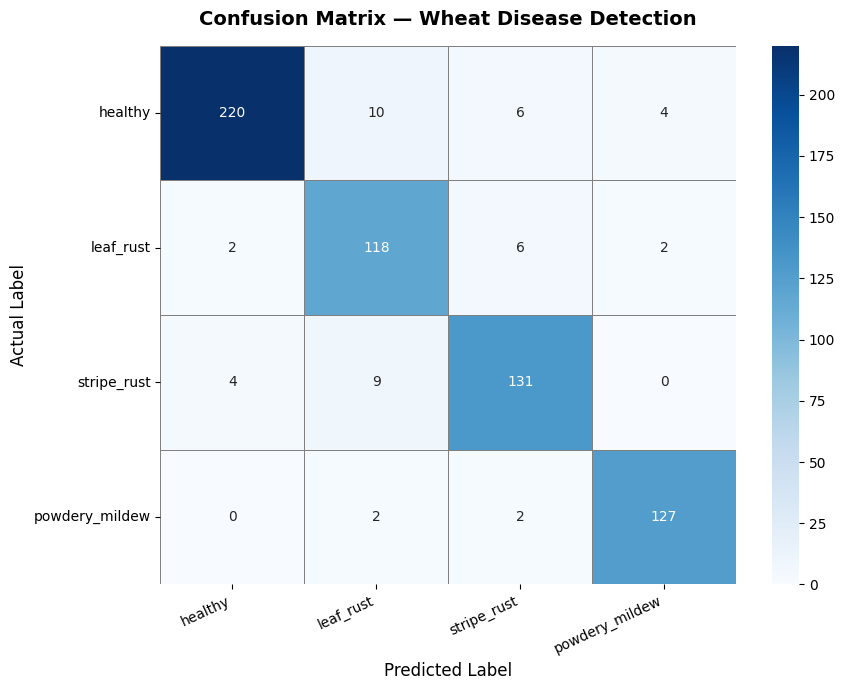

Confusion matrix saved to results/confusion_matrix.png


In [8]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    linewidths=0.5,
    linecolor="gray"
)

plt.title("Confusion Matrix — Wheat Disease Detection",
          fontsize=14, fontweight="bold", pad=15)
plt.ylabel("Actual Label", fontsize=12)
plt.xlabel("Predicted Label", fontsize=12)
plt.xticks(rotation=25, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.savefig(RESULTS_PATH / "confusion_matrix.png", dpi=150)
plt.show()
print("Confusion matrix saved to results/confusion_matrix.png")

# To Show Sample Predictions

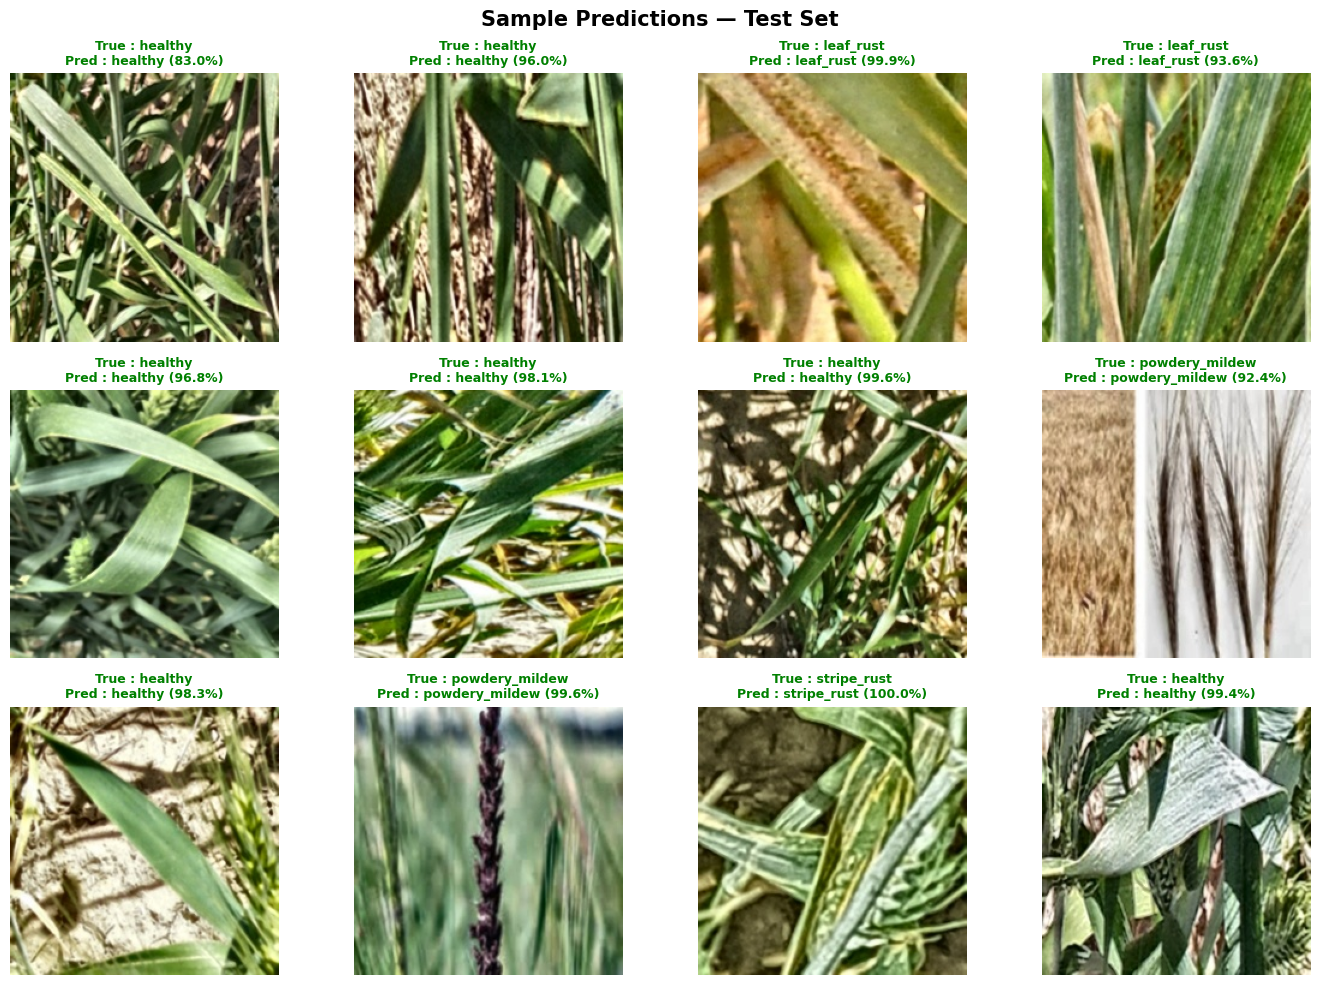

Sample predictions saved to results/sample_predictions.png


In [9]:
import matplotlib.image as mpimg
import random

random.seed(42)

# collect test image paths and true labels
all_images = []
for cls in CLASSES:
    folder = PROCESSED_PATH / "test" / cls
    for img_path in folder.glob("*.jpg"):
        all_images.append((img_path, cls))

# pick 12 random samples
samples = random.sample(all_images, 12)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
fig.suptitle("Sample Predictions — Test Set",
             fontsize=15, fontweight="bold")

for idx, (img_path, true_label) in enumerate(samples):
    row = idx // 4
    col = idx % 4

    # load and preprocess for display
    img_display = mpimg.imread(str(img_path))

    # preprocess for prediction
    img_array = tf.keras.preprocessing.image.load_img(
        str(img_path), target_size=IMG_SIZE)
    img_array = tf.keras.preprocessing.image.img_to_array(img_array)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    # predict
    pred = model.predict(img_array, verbose=0)
    pred_label = CLASSES[np.argmax(pred)]
    confidence = np.max(pred) * 100

    # display
    axes[row][col].imshow(img_display)
    axes[row][col].axis("off")

    color = "green" if pred_label == true_label else "red"
    axes[row][col].set_title(
        f"True : {true_label}\nPred : {pred_label} ({confidence:.1f}%)",
        fontsize=9, color=color, fontweight="bold"
    )

plt.tight_layout()
plt.savefig(RESULTS_PATH / "sample_predictions.png", dpi=150,
            bbox_inches="tight")
plt.show()
print("Sample predictions saved to results/sample_predictions.png")

# Final Evaluation Summary

In [10]:
# per class accuracy
print("=" * 55)
print("       FINAL EVALUATION SUMMARY")
print("=" * 55)
print(f"  Model             : MobileNetV2 (Transfer Learning)")
print(f"  Test Images       : {len(y_true)}")
print(f"  Overall Accuracy  : {accuracy * 100:.2f}%")
print()

# per class results
for i, cls in enumerate(CLASSES):
    cls_mask     = y_true == i
    cls_correct  = np.sum((y_pred == i) & cls_mask)
    cls_total    = np.sum(cls_mask)
    cls_accuracy = cls_correct / cls_total * 100
    print(f"  {cls:<20} : {cls_correct}/{cls_total} correct ({cls_accuracy:.1f}%)")

print()
print(f"  Confusion matrix  : results/confusion_matrix.png")
print(f"  Classification    : results/classification_report.txt")
print(f"  Sample preds      : results/sample_predictions.png")
print("=" * 55)
print("  Evaluation complete. Proceed to Notebook 05.")
print("=" * 55)

       FINAL EVALUATION SUMMARY
  Model             : MobileNetV2 (Transfer Learning)
  Test Images       : 643
  Overall Accuracy  : 92.69%

  healthy              : 220/240 correct (91.7%)
  leaf_rust            : 118/128 correct (92.2%)
  stripe_rust          : 131/144 correct (91.0%)
  powdery_mildew       : 127/131 correct (96.9%)

  Confusion matrix  : results/confusion_matrix.png
  Classification    : results/classification_report.txt
  Sample preds      : results/sample_predictions.png
  Evaluation complete. Proceed to Notebook 05.
